**Q2. CAPM Performance Across Business Cycles**

Data Preparation

In [ ]:
import pandas as pd
import numpy as np

port = pd.read_csv(
    "Portfolios_Formed_on_ME_Daily.csv",
    skiprows=12,
    low_memory=False
)

port = port.rename(columns={port.columns[0]: "date"})
port["date"] = pd.to_datetime(port["date"], format="%Y%m%d", errors="coerce")
port = port.dropna(subset=["date"])
port = port.replace([-99.99, -999], pd.NA)
port.iloc[:, 1:] = port.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
port.iloc[:, 1:] = port.iloc[:, 1:] / 100
port.head()
#port.describe()

,date,<= 0,Lo 30,Med 40,Hi 30,Lo 20,Qnt 2,Qnt 3,Qnt 4,Hi 20,Lo 10,Dec 2,Dec 3,Dec 4,Dec 5,Dec 6,Dec 7,Dec 8,Dec 9,Hi 10
0,1926-07-01,-0.9999,0.0039,-0.0015,0.0013,0.0004,0.0021,-0.002,-0.0008,0.0015,0.0057,-0.0013,0.0068,-0.0008,-0.0036,-0.0008,-0.0012,-0.0006,0.0008,0.0017
1,1926-07-02,-0.9999,-0.0011,0.0036,0.0048,-0.0043,0.001,0.0032,0.0044,0.0049,-0.0053,-0.004,0.0016,0.0006,0.0026,0.0037,0.005,0.0041,0.0037,0.0052
2,1926-07-06,-0.9999,-0.0004,0.0031,0.0017,0.0039,0.0001,0.0048,0.0027,0.0015,-0.0033,0.0061,-0.0038,0.0026,0.007,0.0031,0.0015,0.0033,0.0011,0.0016
3,1926-07-07,-0.9999,-0.0023,0.0011,0.001,-0.0001,-0.0049,0.0023,0.0017,0.0009,0.0028,-0.001,-0.004,-0.0055,0.0031,0.0018,0.0018,0.0016,-0.0004,0.0013
4,1926-07-08,-0.9999,-0.0023,0.0017,0.0025,-0.0056,0.0015,0.0013,0.002,0.0025,0.0055,-0.009,0.0004,0.0022,-0.0008,0.0029,0.0019,0.002,0.002,0.0027


In [ ]:
ff = pd.read_csv("ff_daily(1).csv", index_col = 0)
ff = ff.reset_index()
ff = ff.rename(columns={"index": "date"})
ff["date"] = ff["date"].astype(str).str[:8]
ff["date"] = pd.to_datetime(ff["date"], format="%Y%m%d", errors="coerce")
cols = ["Mkt-RF", "SMB", "HML", "RF"]
ff[cols] = ff[cols].apply(pd.to_numeric, errors="coerce")
ff[cols] = ff[cols] / 100
ff = ff.dropna(subset=["date"])
ff.head()

,date,Mkt-RF,SMB,HML,RF
0,1926-07-01,0.0009,-0.0025,-0.0027,0.0001
1,1926-07-02,0.0045,-0.0033,-0.0006,0.0001
2,1926-07-06,0.0017,0.0030,-0.0039,0.0001
3,1926-07-07,0.0009,-0.0058,0.0002,0.0001
4,1926-07-08,0.0022,-0.0038,0.0019,0.0001


In [ ]:
usrec = pd.read_csv("USREC.csv")
usrec["observation_date"] = pd.to_datetime(usrec["observation_date"])
usrec = usrec.rename(columns={"observation_date": "date", "USREC": "recession"})
usrec_daily = (
    usrec.set_index("date")
         .resample("D")
         .ffill()
         .reset_index()
)
usrec.head()

,date,recession
0,1996-01-01,0
1,1996-02-01,0
2,1996-03-01,0
3,1996-04-01,0
4,1996-05-01,0


In [ ]:
df = port.merge(ff, on="date", how="inner")
df = df.merge(usrec_daily, on="date", how="left")
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.to_period("M")
df = df[(df["date"] >= "1996-01-01") & (df["date"] <= "2025-12-31")]
df["recession"] = df["recession"].ffill()
df["recession"].isna().sum()

np.int64(0)

**a) Estimation**

In [ ]:
#CAPM Function

import statsmodels.api as sm

def monthly_capm(data, portfolio):
    results = []
    df = data.copy()

    df[portfolio] = pd.to_numeric(df[portfolio], errors='coerce')
    df['Mkt-RF'] = pd.to_numeric(df['Mkt-RF'], errors='coerce')
    df['RF'] = pd.to_numeric(df['RF'], errors='coerce')

    df['excess_return'] = df[portfolio] - df['RF']

    df = df.dropna(subset=['excess_return', 'Mkt-RF', 'month'])

    grouped = df.groupby("month")

    for m, group in grouped:
        if len(group) >= 5:  # minimum observations for regression
            y = group["excess_return"]  # excess returns
            X = sm.add_constant(group["Mkt-RF"])  # market excess returns

            try:
                model = sm.OLS(y, X, missing="drop").fit()

                results.append({
                    "month": str(m),
                    "alpha": model.params["const"],
                    "beta": model.params["Mkt-RF"],
                    "alpha_pval": model.pvalues["const"],
                    "beta_pval": model.pvalues["Mkt-RF"],
                    "r_squared": model.rsquared,
                    "n_obs": len(group)
                })
            except Exception as e:
                print(f"Warning: Could not run regression for {m}: {e}")
                continue

    return pd.DataFrame(results)

lo10_monthly = monthly_capm(df, "Lo 10")
hi10_monthly = monthly_capm(df, "Hi 10")

print("Lo 10 Portfolio Results:")
print(lo10_monthly.head())
print("\nHi 10 Portfolio Results:")
print(hi10_monthly.head())

Lo 10 Portfolio Results:
     month     alpha      beta    alpha_pval     beta_pval  r_squared  n_obs
0  1996-01  0.001747  0.475058  4.324120e-03  1.971459e-07   0.478788     44
1  1996-02  0.001923  0.299063  6.465083e-05  3.116348e-05   0.370147     40
2  1996-03  0.001688  0.536572  1.348004e-02  4.278037e-08   0.532012     42
3  1996-04  0.002988  0.451895  9.634224e-08  1.660547e-07   0.499890     42
4  1996-05  0.004099  0.443323  5.605206e-08  3.279462e-05   0.339940     44

Hi 10 Portfolio Results:
     month     alpha      beta  alpha_pval     beta_pval  r_squared  n_obs
0  1996-01  0.000371  1.010604    0.128730  4.091299e-31   0.960555     44
1  1996-02 -0.000470  1.181363    0.028525  3.718258e-32   0.975316     40
2  1996-03 -0.000051  1.089041    0.842047  7.825882e-32   0.969137     42
3  1996-04 -0.000644  1.085469    0.003791  8.085177e-31   0.965318     42
4  1996-05 -0.000293  1.082705    0.168312  4.523916e-32   0.964479     44


**b) Analysis**

In [ ]:
monthly_recession = df.groupby('month')['recession'].max()
recession_map = monthly_recession.to_dict()
lo10_monthly['recession'] = lo10_monthly['month'].map(recession_map)
hi10_monthly['recession'] = hi10_monthly['month'].map(recession_map)
print("Recession months in sample:")
print(lo10_monthly[lo10_monthly['recession'] == 1][['month', 'recession']].head(10))
print(f"\nTotal recession months: {lo10_monthly['recession'].sum()}")
print(f"Total expansion months: {len(lo10_monthly) - lo10_monthly['recession'].sum()}")

Recession months in sample:
       month  recession
63   2001-04        1.0
64   2001-05        1.0
65   2001-06        1.0
66   2001-07        1.0
67   2001-08        1.0
68   2001-09        1.0
69   2001-10        1.0
70   2001-11        1.0
144  2008-01        1.0
145  2008-02        1.0

Total recession months: 28.0
Total expansion months: 332.0


In [ ]:
lo10_recession = lo10_monthly[lo10_monthly['recession'] == 1]
lo10_expansion = lo10_monthly[lo10_monthly['recession'] == 0]
hi10_recession = hi10_monthly[hi10_monthly['recession'] == 1]
hi10_expansion = hi10_monthly[hi10_monthly['recession'] == 0]

print("Lo 10 Portfolio - Recession vs Expansion --------------------------------")
print(f"\nRecession Periods ({len(lo10_recession)} months):")
print(f"  Mean Alpha: {lo10_recession['alpha'].mean():.6f} ({lo10_recession['alpha'].mean()*12*100:.2f}% annualized)")
print(f"  Mean Beta:  {lo10_recession['beta'].mean():.4f}")
print(f"  Alpha Std:  {lo10_recession['alpha'].std():.6f}")
print(f"  Beta Std:   {lo10_recession['beta'].std():.4f}")

print(f"\nExpansion Periods ({len(lo10_expansion)} months):")
print(f"  Mean Alpha: {lo10_expansion['alpha'].mean():.6f} ({lo10_expansion['alpha'].mean()*12*100:.2f}% annualized)")
print(f"  Mean Beta:  {lo10_expansion['beta'].mean():.4f}")
print(f"  Alpha Std:  {lo10_expansion['alpha'].std():.6f}")
print(f"  Beta Std:   {lo10_expansion['beta'].std():.4f}")

print("\nHi 10 Portfolio - Recession vs Expansion --------------------------------")
print(f"\nRecession Periods ({len(hi10_recession)} months):")
print(f"  Mean Alpha: {hi10_recession['alpha'].mean():.6f} ({hi10_recession['alpha'].mean()*12*100:.2f}% annualized)")
print(f"  Mean Beta:  {hi10_recession['beta'].mean():.4f}")
print(f"  Alpha Std:  {hi10_recession['alpha'].std():.6f}")
print(f"  Beta Std:   {hi10_recession['beta'].std():.4f}")

print(f"\nExpansion Periods ({len(hi10_expansion)} months):")
print(f"  Mean Alpha: {hi10_expansion['alpha'].mean():.6f} ({hi10_expansion['alpha'].mean()*12*100:.2f}% annualized)")
print(f"  Mean Beta:  {hi10_expansion['beta'].mean():.4f}")
print(f"  Alpha Std:  {hi10_expansion['alpha'].std():.6f}")
print(f"  Beta Std:   {hi10_expansion['beta'].std():.4f}")

Lo 10 Portfolio - Recession vs Expansion --------------------------------

Recession Periods (28 months):
  Mean Alpha: 0.000381 (0.46% annualized)
  Mean Beta:  0.6112
  Alpha Std:  0.002711
  Beta Std:   0.2397

Expansion Periods (332 months):
  Mean Alpha: 0.000231 (0.28% annualized)
  Mean Beta:  0.7769
  Alpha Std:  0.002195
  Beta Std:   0.3575

Hi 10 Portfolio - Recession vs Expansion --------------------------------

Recession Periods (28 months):
  Mean Alpha: 0.000123 (0.15% annualized)
  Mean Beta:  1.0542
  Alpha Std:  0.000530
  Beta Std:   0.0865

Expansion Periods (332 months):
  Mean Alpha: 0.000014 (0.02% annualized)
  Mean Beta:  0.9681
  Alpha Std:  0.000398
  Beta Std:   0.0772


In [ ]:
# t-test
from scipy.stats import ttest_ind

def compare_regimes(portfolio_name, recession_data, expansion_data, metric):
    """
    Perform t-test comparing recession vs expansion for a given metric
    """
    t_stat, p_value = ttest_ind(recession_data[metric], expansion_data[metric])

    mean_diff = recession_data[metric].mean() - expansion_data[metric].mean()

    print(f"\n{portfolio_name} - {metric}:")
    print(f"  Recession mean: {recession_data[metric].mean():.6f}")
    print(f"  Expansion mean: {expansion_data[metric].mean():.6f}")
    print(f"  Difference: {mean_diff:.6f}")
    print(f"  T-statistic: {t_stat:.4f}")
    print(f"  P-value: {p_value:.4f}")

    if p_value < 0.01:
        print(f"  Conclusion: Highly significant difference (p < 0.01)")
    elif p_value < 0.05:
        print(f"  Conclusion: Significant difference (p < 0.05)")
    elif p_value < 0.10:
        print(f"  Conclusion: Marginally significant difference (p < 0.10)")
    else:
        print(f"  Conclusion: No statistically significant difference")

    return t_stat, p_value

# Lo 10 tests
print("LO 10 PORTFOLIO (Small Caps) --------------------------------------------")
lo10_alpha_t, lo10_alpha_p = compare_regimes("Lo 10", lo10_recession, lo10_expansion, "alpha")
lo10_beta_t, lo10_beta_p = compare_regimes("Lo 10", lo10_recession, lo10_expansion, "beta")

# Hi 10 tests
print("\nHI 10 PORTFOLIO (Large Caps) --------------------------------------------")
hi10_alpha_t, hi10_alpha_p = compare_regimes("Hi 10", hi10_recession, hi10_expansion, "alpha")
hi10_beta_t, hi10_beta_p = compare_regimes("Hi 10", hi10_recession, hi10_expansion, "beta")

LO 10 PORTFOLIO (Small Caps) --------------------------------------------

Lo 10 - alpha:
  Recession mean: 0.000381
  Expansion mean: 0.000231
  Difference: 0.000150
  T-statistic: 0.3401
  P-value: 0.7340
  Conclusion: No statistically significant difference

Lo 10 - beta:
  Recession mean: 0.611194
  Expansion mean: 0.776917
  Difference: -0.165724
  T-statistic: -2.4058
  P-value: 0.0166
  Conclusion: Significant difference (p < 0.05)

HI 10 PORTFOLIO (Large Caps) --------------------------------------------

Hi 10 - alpha:
  Recession mean: 0.000123
  Expansion mean: 0.000014
  Difference: 0.000109
  T-statistic: 1.3542
  P-value: 0.1765
  Conclusion: No statistically significant difference

Hi 10 - beta:
  Recession mean: 1.054185
  Expansion mean: 0.968134
  Difference: 0.086052
  T-statistic: 5.6081
  P-value: 0.0000
  Conclusion: Highly significant difference (p < 0.01)


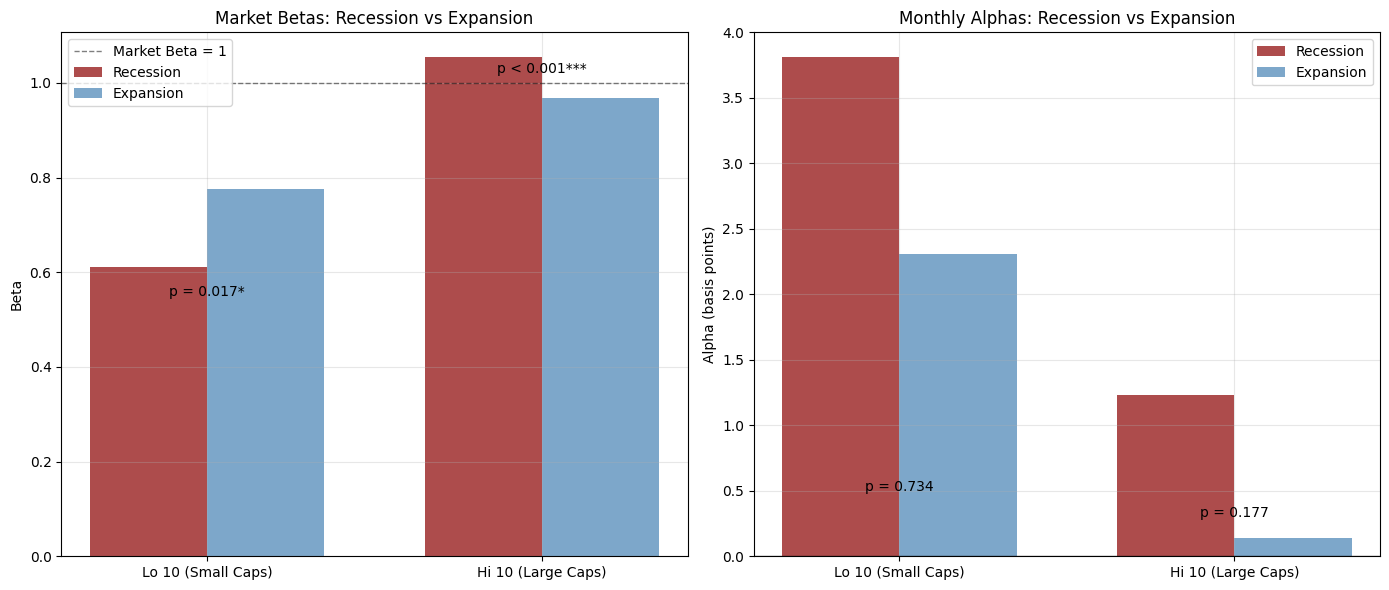

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

portfolios = ['Lo 10 (Small Caps)', 'Hi 10 (Large Caps)']
recession_betas = [0.611194, 1.054185]
expansion_betas = [0.776917, 0.968134]
beta_errors = [0.0688, 0.0153]

x = np.arange(len(portfolios))
width = 0.35

axes[0].bar(x - width/2, recession_betas, width, label='Recession', color='darkred', alpha=0.7)
axes[0].bar(x + width/2, expansion_betas, width, label='Expansion', color='steelblue', alpha=0.7)
axes[0].axhline(y=1, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Market Beta = 1')
axes[0].set_ylabel('Beta')
axes[0].set_title('Market Betas: Recession vs Expansion')
axes[0].set_xticks(x)
axes[0].set_xticklabels(portfolios)
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].annotate('p = 0.017*', xy=(0, 0.55), ha='center', fontsize=10)
axes[0].annotate('p < 0.001***', xy=(1, 1.02), ha='center', fontsize=10)

recession_alphas_bps = [0.000381*10000, 0.000123*10000]
expansion_alphas_bps = [0.000231*10000, 0.000014*10000]

axes[1].bar(x - width/2, recession_alphas_bps, width, label='Recession', color='darkred', alpha=0.7)
axes[1].bar(x + width/2, expansion_alphas_bps, width, label='Expansion', color='steelblue', alpha=0.7)
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
axes[1].set_ylabel('Alpha (basis points)')
axes[1].set_title('Monthly Alphas: Recession vs Expansion')
axes[1].set_xticks(x)
axes[1].set_xticklabels(portfolios)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[1].annotate('p = 0.734', xy=(0, 0.5), ha='center', fontsize=10)
axes[1].annotate('p = 0.177', xy=(1, 0.3), ha='center', fontsize=10)

plt.tight_layout()
plt.show()

Interpretation:

For small-cap stocks (Lo 10 Portfolio):
* No significant difference for alpha values between recessions (0.038% monthly) and expansions (0.023% monthly), indicated by p = 0.734 > 0.10.
* Small caps show significantly lower beta during recessions (0.611 vs. 0.777 during expansions), indicated by p = 0.017 < 0.01.
* Beta drops by 0.166 (around 21%) during recessions.

For large-cap stocks (Hi 10 Portfolio):
* No significant difference between recessions and expansions (0.012% vs. 0.001% monthly), as indicated by p = 0.177 > 0.10.
* Large caps show significantly higher beta during recessions (1.054 vs. 0.968 during expansions), as seen from p < 0.001.
* Beta increases by 0.086 (approximately 9%) during recessions.

The contrasting beta behavior supports the **flight-to-quality phenomenon**. Large caps become more market-sensitive during recessions (beta increases to 1.054) as investors flock to "safer" stocks, making such stocks move more closely with the overall market. Meanwhile, small caps become less market sensitive as beta dips to 0.611 as a result of investors abandoning them, causing them to deviate from market movements. This finding contradicts the traditional **leverage theory**, which predicts that small-cap betas would increase during recessions due to higher financial leverage.

Additionally, the beta pattern suggests that for small caps, during recessions, liquidity dries up and investors avoid distressed assets. Small caps trade more on idiosyncratic factors (e.g. survival prospects and refinancing ability) rather than market movements, which reduces their market beta. Large caps, on the other hand, remain liquid and become the primary method of market exposure, increasing their systematic risk loading. Liquidity premium is expected to increase according to the **liquidity risk theory**, which is supported by the decreased Lo 10 beta and the increased Hi 10 beta.

The significant alpha differences suggest that the market is efficient (the market already prices recession risks for both portfolio sizes). There are also no abnormal opportunities as neither portfolio generates superior risk-adjusted returns during recessions. These indicate that the beta changes appropriately reflect changing systematic risk, leaving no alpha.



**c) Research Design Extension**

**Proposed continuous macroeconomic variable:**

slope of yield curve (10-year treasury yield - 2-year treasury yield)

**Reason:**

the slope of the yield curve is a leading indicator as it predicts recessions 12-18 months in advance. The variable also varies continuously, which captures grey areas between expansion and recession, and changing risk premiums and credit conditions. Additionally, its economic mechanism reflects monetary policy stance and growth expectations.

**Modification of CAPM Regression Equation:**

To capture the continuous nature of changing economic conditions, I would propose to include an interaction term between market excess returns and the yield spread to the existing CAPM model:

$R_{p,t} - R_{f,t} = \alpha + \beta_1 (R_{m,t} - R_{f,t}) + \beta_2 S_t + \beta_3 (R_{m,t} - R_{f,t}) \times S_t + \varepsilon_t$

where $S_t$ is the yield spread at time $t$, defined as the 10-year treasury yield minus the 2-year treasury yield.

The coefficient $\beta_1$ represents the market beta when the yield spread is zero (neutral economic conditions), while $\beta_3$ captures how this beta changes as the yield spread varies. A positive $\beta_3$ indicates that market sensitivity increases during economic expansions (when the spread widens), whereas a negative $\beta_3$ suggests counter-cyclical betas.

The direct effect of the yield spread on returns is captured by $\beta_2$, which measures the independent impact of economic conditions on portfolio returns beyond their effect through market risk.